<a href="https://colab.research.google.com/github/ashah778/Project-2-DATA-201/blob/main/Arnav%20Shah%20Final%20Project%202.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## DATA 201 Project 2: Regression Trees and Random Forests

## Part 1 - Finding and Introducing my dataset


Question 1-3:

My Dataset is called: Estimation of Obesity Levels Based on Eating Habits and Physical Condition.

My Source of the Dataset: UCI Machine Learning Repository

Link to my Dataset Website Below:

https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition



My Research Question is:

Can I use an individual's personal characteristics and lifestyle habits to predict their weight using regression models?

My Dataset:

For this project I am using the Estimation of Obesity Levels Based on Eating Habits and Physical Condition dataset from the UCI Machine Learning Repository.

The dataset contains information about individuals and their lifestyle habits which includes age gender height weight eating habits and physical activity.

I chose this dataset because it connects to real-life situations and shows how everyday habits and lifestyle choices can relate to a person's weight. I wanted to explore how data can be used to understand patterns in everyday life.

My goal is to predict an individual's weight using the other available characteristics as predictors. I will build a Decision Tree Regressor and a Random Forest Regressor and compare their accuracy using RMSE.

This will help me understand how machine learning can use real-world data to identify patterns and make predictions

Question 4: Loading and Exploring my Dataset

In [95]:

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.tree import DecisionTreeRegressor, plot_tree

from sklearn.model_selection import cross_val_score, KFold

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error






In [96]:
# I am loading the obesity dataset
obesity  = pd.read_csv('/content/drive/MyDrive/Data_201 /Datasets/ObesityDataSet_raw_and_data_sinthetic.csv')

# I am displaying the first five rows.
obesity.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [97]:
# Source: Textbook Chapters and Project 1 (Data Cleaning)

# I am displaying the number of rows and columns.
print("Dataset shape:", obesity.shape)

# I am displaying the column names.
print(obesity.columns)

# I am checking every column for missing values.
print("Missing values:")
print(obesity.isnull().sum())



Dataset shape: (2111, 17)
Index(['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight',
       'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE',
       'CALC', 'MTRANS', 'NObeyesdad'],
      dtype='object')
Missing values:
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64


In [98]:
# Source: Textbook Chapters and Project 1 (Data Cleaning)

# I am removing rows that contain missing values.
obesity = obesity.dropna()

# I am displaying the cleaned dataset shape.
print("Cleaned dataset shape:", obesity.shape)

# I am checking for missing values after cleaning.
print("Missing values after cleaning:")
print(obesity.isnull().sum())

Cleaned dataset shape: (2111, 17)
Missing values after cleaning:
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64


Analysis:

I first checked the dataset's size, column names and missing values. I also looked at the first five rows to get familiar with the data. I used dropna() to remove rows with missing values.

I noticed there were no missing values which is why no rows were removed. The cleaned dataset still had 2,111 rows and 17 columns. I also did not remove any columns. I used one-hot encoding in Question 5 to convert categorical predictors into numerical values for the models.

## Part 2 - Prepare Data and Fit a Single Tree

Question 5: Seperating my Predictors as well as Target to Split my Data

In [99]:

# Source: Lab 9

# I am separating the predictor variables and target variable.
X = obesity.drop(columns=['Weight', 'NObeyesdad'])

# I am setting Weight as my target variable.
y = obesity['Weight']

# I am using one-hot encoding to convert categorical predictors into numerical columns.
X = pd.get_dummies(X, drop_first=True).astype(float)

# I am displaying the first five rows of my encoded predictors.
display(X.head())

# I am displaying the predictor columns and target.
print("Predictors:", X.columns)
print("Target:", y.name)

# I am splitting the data into training 70% and testing 30%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=50
)

# I am displaying the training and testing data sizes.
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


,Age,Height,FCVC,NCP,CH2O,FAF,TUE,Gender_Male,family_history_with_overweight_yes,FAVC_yes,...,CAEC_no,SMOKE_yes,SCC_yes,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,21.0,1.62,2.0,3.0,2.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,21.0,1.52,3.0,3.0,3.0,3.0,0.0,0.0,1.0,0.0,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,23.0,1.80,2.0,3.0,2.0,2.0,1.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,27.0,1.80,3.0,3.0,2.0,2.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,22.0,1.78,2.0,1.0,2.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Predictors: Index(['Age', 'Height', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE', 'Gender_Male',
       'family_history_with_overweight_yes', 'FAVC_yes', 'CAEC_Frequently',
       'CAEC_Sometimes', 'CAEC_no', 'SMOKE_yes', 'SCC_yes', 'CALC_Frequently',
       'CALC_Sometimes', 'CALC_no', 'MTRANS_Bike', 'MTRANS_Motorbike',
       'MTRANS_Public_Transportation', 'MTRANS_Walking'],
      dtype='object')
Target: Weight
Training data: (1477, 22)
Testing data: (634, 22)


Question 6: Building my Decision Tree Regressor

In [100]:
# Source: Lab 9

# I am building a Decision Tree Regressor to predict Weight and evaluate
# its training and testing performance.

# I am creating and training the Decision Tree model.
tree = DecisionTreeRegressor(max_depth=None, random_state=50)

# I am training the Decision Tree
tree.fit(X_train, y_train)

# I am calculating training and testing RMSE.
train_rmse = np.sqrt(mean_squared_error(y_train, tree.predict(X_train)))

test_rmse = np.sqrt(mean_squared_error(y_test, tree.predict(X_test)))

# I am displaying the RMSE results.
print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

Training RMSE: 0.0
Testing RMSE: 11.854741099050807


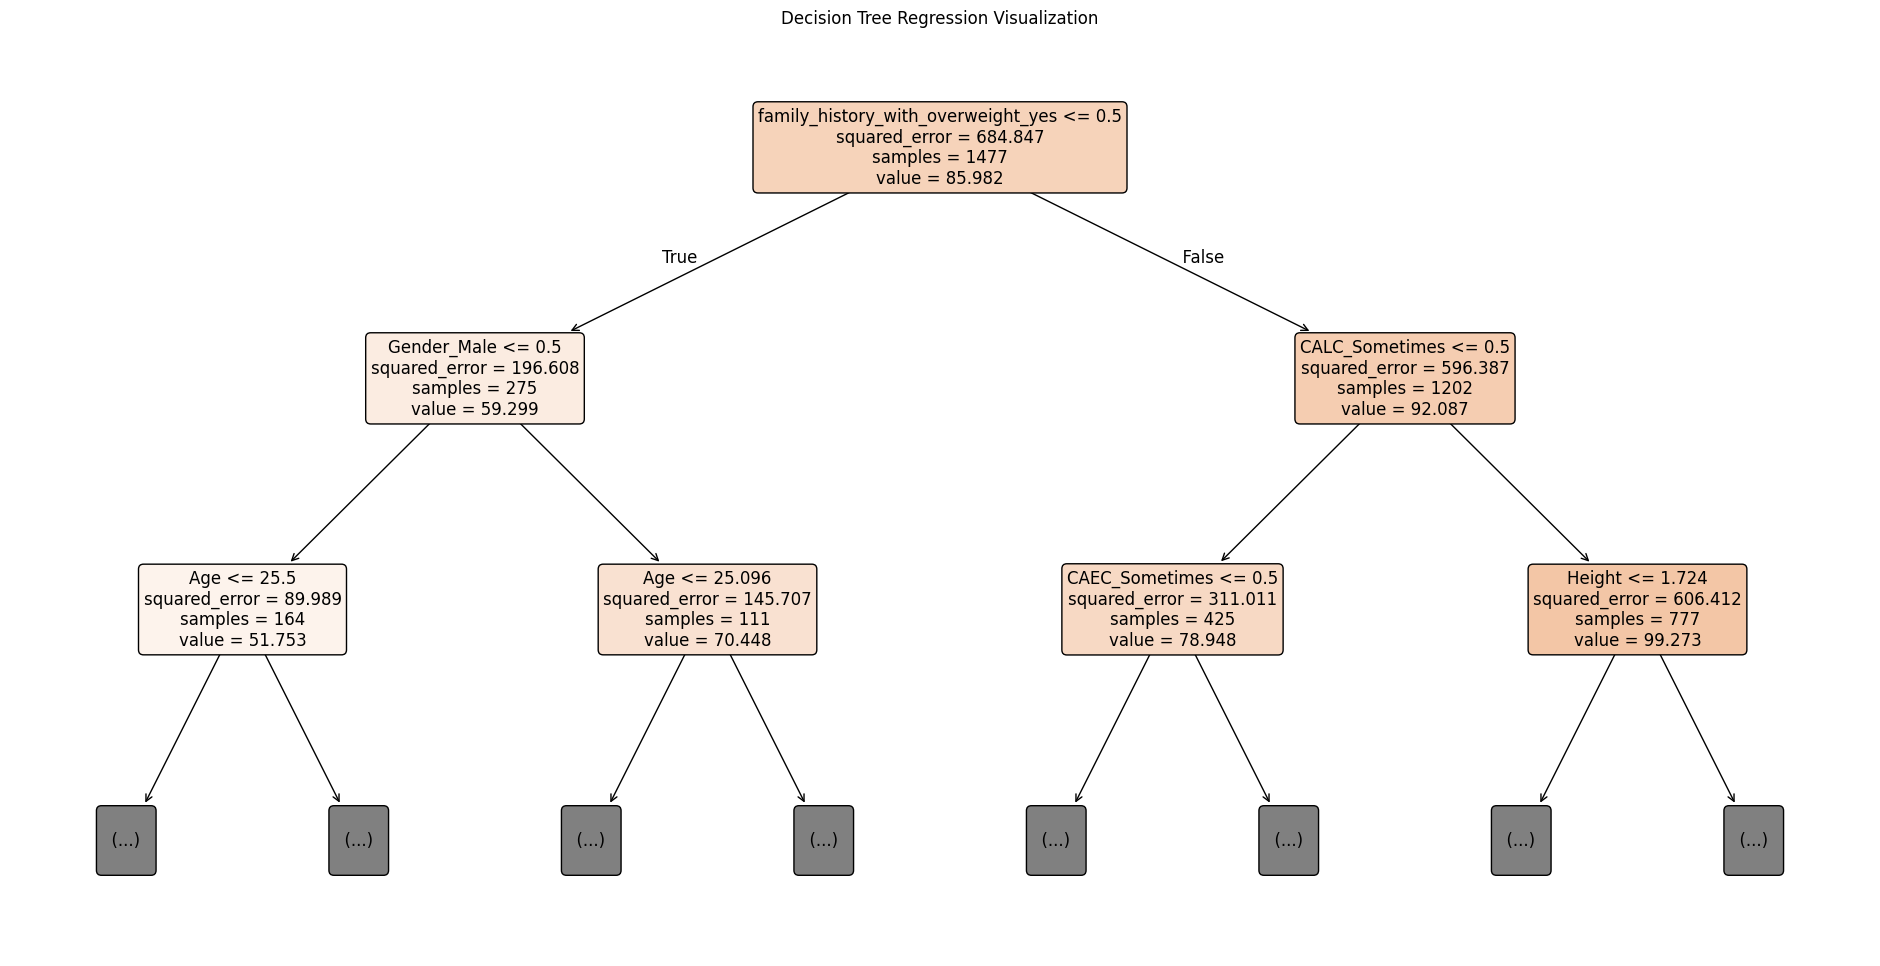

In [101]:
# Source: Lab 9 & 10

# I am setting the size of the Decision Tree Regression Visualization
plt.figure(figsize=(24, 12))

# I am displaying the first two levels of my trained tree.
plot_tree(tree, feature_names=X_train.columns,
    filled=True,
    rounded=True,
    max_depth=2,
    fontsize=12
)

# I am adding a title to my tree visualization
# I am displaying my Decision Tree Regression Visualization
plt.title('Decision Tree Regression Visualization')
plt.show()

## Part 3 - Build and Compare Random Forest

Question 7: Building my Random Forest Regressor

In [103]:
# Source: Lab 9 & Lab 10

# I am building a Random Forest to compare its prediction performance with my Decision Tree
forest = RandomForestRegressor(n_estimators=100, random_state=50, n_jobs=-1)

# I am training the Random Forest
forest.fit(X_train, y_train)

# I am calculating training and testing RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, forest.predict(X_train)))

test_rmse = np.sqrt(mean_squared_error(y_test, forest.predict(X_test)))

# I am displaying the training and test RMSE results
print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

Training RMSE: 3.3297392546092377
Testing RMSE: 8.056660355778906


Question 8: Comparing Both Models

In [104]:
# Source: Lab 8

# I am comparing the Decision Tree and Random Forest models to determine which predicts unseen data more accurately.
# I am defining a function to calculate the training and testing RMSE.
def measure(name, model):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {
        'Model': name,
        'Training RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Testing RMSE': np.sqrt(mean_squared_error(y_test, test_pred))
    }

# I am comparing the Decision Tree and Random Forest models.
results = [
    measure('Decision Tree', tree),
    measure('Random Forest', forest)
]

# I am displaying the comparison table.
display(pd.DataFrame(results).round(2))


,Model,Training RMSE,Testing RMSE
0,Decision Tree,0.00,11.85
1,Random Forest,3.33,8.06


Analysis (Question 6 & 8):

6. Explain whether the results suggest overfitting.

The results do suggest that the Decision Tree ended up overfitting the training data. The reason is because it eneded up fitting the training data perfect. But a negative effect was that the performance ended up being poor on the dataset that was not seen.

8. Which model predicts unseen values more accurately? Explain using your results.

The Decision Tree had a training RMSE of 0.00 and a testing RMSE of 11.85. This means that it learned the training data too closely and did not perform as well on new data.

The Random Forest had a training RMSE of 3.33 and a lower testing RMSE of 8.06. From analyzing these results I believe the Random Forest was the better model due to it making more accurate predictions on the data that was used for testing.

## Part 4 -Investigate two random forest parameters

Question 9: Investigating the Number of Trees

In [80]:
# Source: Labs 4–6

# I am investigating how changing the number of trees affects Random Forest performance using 5-fold cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=50)

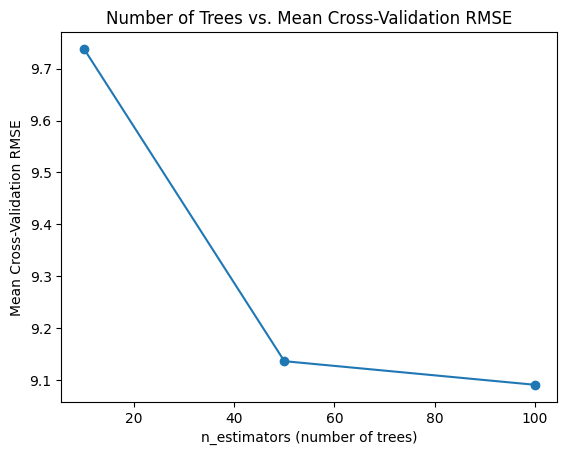

,Number of Trees,Mean CV RMSE
0,10,9.74
1,50,9.14
2,100,9.09


In [78]:
# Source: Lab 9 and Lab 10

# I am comparing Random Forests with different numbers of trees.
tree_counts = [10, 50, 100]

# I am storing the cross-validation RMSE results.
cv_rmse = []

# I am calculating the 5-fold cross-validation RMSE for each model.
for n in tree_counts:
    forest = RandomForestRegressor(n_estimators=n, max_depth=None, random_state=50, n_jobs=-1)
    scores = cross_val_score(forest, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
    cv_rmse.append(-scores.mean())

# I am plotting the number of trees against the mean cross-validation RMSE.
plt.plot(tree_counts, cv_rmse, marker='o')
plt.xlabel('n_estimators (number of trees)')
plt.ylabel('Mean Cross-Validation RMSE')
plt.title('Number of Trees vs. Mean Cross-Validation RMSE')
plt.show()

# I am displaying the cross-validation results
display(pd.DataFrame({
    'Number of Trees': tree_counts,
    'Mean CV RMSE': np.round(cv_rmse, 2)
}))

Analysis (Based on graph):

What happens as you add trees?

The graphs trend shows that when I increased the number of trees from 10 to 50, the mean cross-validation RMSE decreased from approximately 9.8 to 9.15. Basically when I increased the number of trees from 50 to 100, the RMSE decreased slightly more to approximately 9.12.

I can conclude that the addition of more trees improved the Random Forest predictions for an individuals weight. Also I noticed that improvement became smaller after 50 trees which means there was improvement but was much smaller.

Question 10: Investigating Maximum Tree Depth

,Maximum Depth,Mean CV RMSE
0,2,19.96
1,4,14.68
2,8,9.86
3,12,9.15


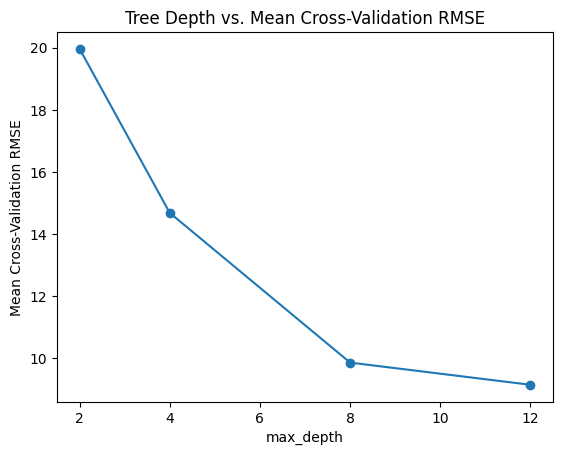

In [79]:
# Source: Lab 9 & Lab 10

# I am selecting four maximum depths to compare.
depths = [2, 4, 8, 12]

# I am creating an empty list to store the RMSE results.
depth_scores = []

# I am calculating the 5-fold cross-validation RMSE for each maximum depth.
for d in depths:
    forest = RandomForestRegressor(n_estimators= 100, max_depth=d, random_state=50, n_jobs=-1)
    scores = cross_val_score(forest, X_train, y_train, cv=5,scoring='neg_root_mean_squared_error')
    depth_scores.append(-scores.mean())

# I am displaying the cross-validation results.
display(pd.DataFrame({
    'Maximum Depth': depths,
    'Mean CV RMSE': np.round(depth_scores, 2)
}))

# I am plotting maximum tree depth against mean cross-validation RMSE.
plt.plot(depths, depth_scores, marker='o')
plt.xlabel('max_depth')
plt.ylabel('Mean Cross-Validation RMSE')
plt.title('Tree Depth vs. Mean Cross-Validation RMSE')
plt.show()

Analysis (Based on graph):

How does limiting depth affect
performance?

I noticed that as I increased the maximum tree depth from 2 to 4 which means the mean cross-validation RMSE decreased from approximately 20 to 14.5.

I also noticed increasing the depth to 8 lowered it further to about 9.8. At depth 12 it was also at about 9.1.

Based on this I learned that the trees improved my Random Forest's ability to identify patterns for individuals personal characteristics and lifestyle habits in terms of predicting weight. I also learned that the improvement became smaller between depths 8 and 12 since the mean CV RMSE only decreased from 9.86 at depth 8 to 9.15 at depth 12.

Question 11: Selecting and Evaluating the Final Random Forest Model

In [84]:
# Source: Lab 9 & Lab 10

# I am selecting the best based on the most successful cross-validation RMSE.
best_n = tree_counts[(np.argmin(cv_rmse))]
best_depth = depths[np.argmin(depth_scores)]

# I am creating the final Random Forest model.
final_forest = RandomForestRegressor(n_estimators=best_n, max_depth=best_depth, random_state=50, n_jobs=-1
)

# I am fitting the final Random Forest model.
final_forest.fit(X_train, y_train)

# I am calculating the training and testing RMSE.
train_rmse = np.sqrt(mean_squared_error(y_train, final_forest.predict(X_train)))
test_rmse = np.sqrt(mean_squared_error(y_test, final_forest.predict(X_test)))


# I am displaying the best settings and final model results.
print("Best number of trees:", best_n)
print("Best maximum depth:", best_depth)
print("Final Forest, RMSE on training set:", round(train_rmse, 2))
print("Final Forest, RMSE on test set: ", round(test_rmse, 2))



Best number of trees: 100
Best maximum depth: 12
Final Forest, RMSE on training set: 3.77
Final Forest, RMSE on test set:  8.18


Analysis: Briefly compare it with your original tree and forest.

My final Random Forest used 100 trees and a maximum depth of 12. The testing RMSE was 8.18, which was lower than the original Decision Tree's 11.85. But it was slightly higher than the original Random Forest's 8.06.

From those results, I can conclude that my final tuned model performed better than the Decision Tree, but it did not improve for the testing RMSE compared with the original Random Forest.



## Part 5 - Feature Importance and Interpretation

Question 12: Visualizing the Top 10 Most Important Predictors

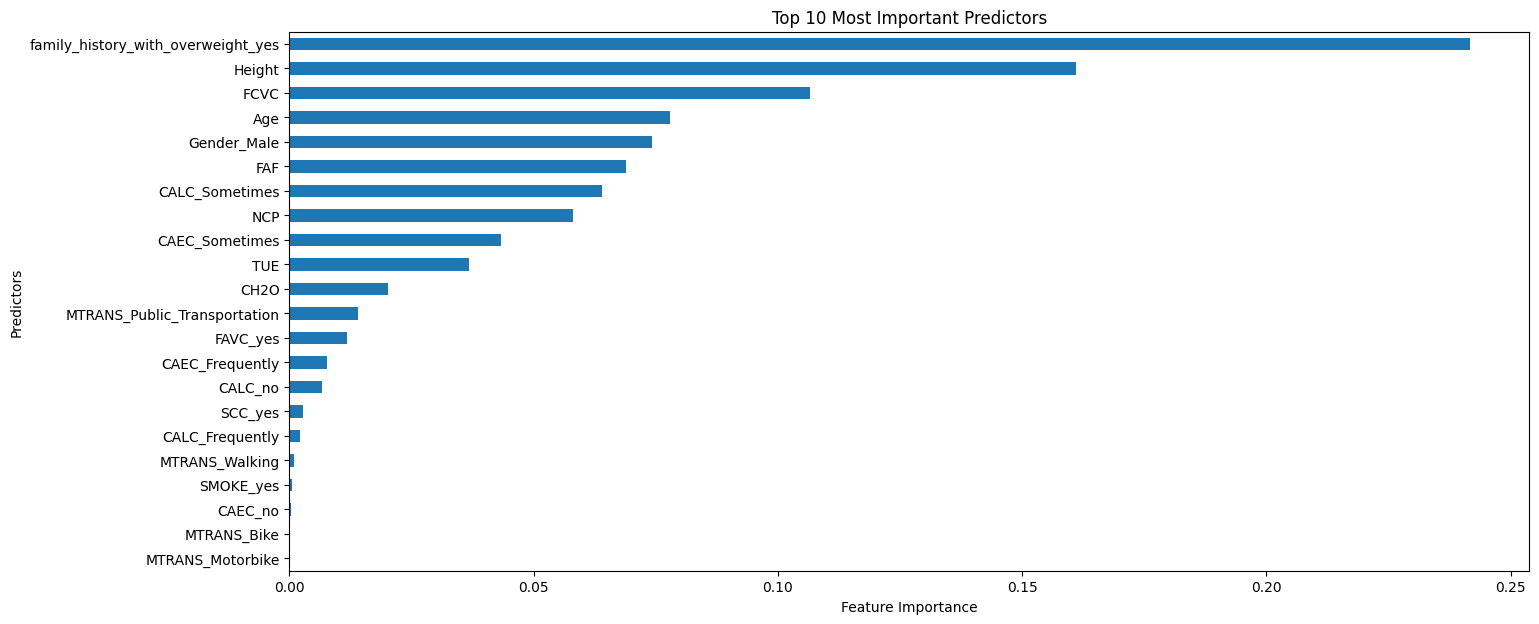

In [94]:
# Source: Lab 9

# I am organizing the feature importances with their predictor names.
imp = pd.Series(final_forest.feature_importances_, index=X_train.columns).sort_values()

# I am selecting predictors with feature importance greater than zero.
imp[imp > 0].plot(kind='barh', figsize=(16, 7))

# I am labeling and displaying my graph
plt.xlabel("Feature Importance")
plt.ylabel("Predictors")
plt.title("Top 10 Most Important Predictors")
plt.show()

In [93]:
# Source: Lab 9 & Lab 10

# I am organizing the feature importances.
imp = pd.Series(final_forest.feature_importances_, index=X_train.columns)

# I am sorting the feature importances.
imp = imp.sort_values()[::-1]

# I am selecting the top 10 features.
top_10 = imp[:10]

# I am displaying the top 10 features.
print(top_10)

family_history_with_overweight_yes    0.241769
Height                                0.161126
FCVC                                  0.106580
Age                                   0.077974
Gender_Male                           0.074170
FAF                                   0.068903
CALC_Sometimes                        0.063968
NCP                                   0.057964
CAEC_Sometimes                        0.043381
TUE                                   0.036799
dtype: float64


Question 13: Identifying the Three Most Important Predictors

Analysis:

The three most important predictors were family history with overweight (0.242), height (0.161) and FCVC (0.107). From the graph and table I noticed Family history had the highest importance at 24.18%. Then Height had the second most at about 16.11% followed by vegetable consumption which was at 10.66%. These features helped the model identify patterns when predicting the weight.

The other predictors which were valuable from the results were age (7.81%), gender (7.39%) and physical activity (6.86%). These features were important due to it feeding the model valuable information.

Feature importance also displays the features which assisted with predictions. I learned that feature importance displays the amount each feature helped my model make predictions. However, It does not prove that a feature causes changes in weight to happen.

Question 14 (Conclusion):

In this project, I predicted a person's weight and compared a Decision Tree Regressor with a Random Forest Regressor. I learned that the Random Forest performed better because it had a lower test RMSE than the Decision Tree.

Testing different numbers of trees (n_estimators) helped me understand the way that increasing the number of trees improved the model's predictions. However I learned that the improvement became smaller after 50 trees.

Testing different maximum depths (max_depth) helped me learn how deeper trees generally had lower the cross-validation RMSE which allowed the model to identify more patterns in the data.

One limitation of my analysis is that the dataset might not represent everyone which ultimately means the model might not make accurate predictions fully.